Basic Data Evaluation of AgentrecBench

In [3]:
!pip -q install huggingface_hub pandas

from huggingface_hub import HfApi

repo = "SGJQovo/AgentRecBench"
api = HfApi()

files = api.list_repo_files(
    repo_id=repo,
    repo_type="dataset"
)

print("Total files:", len(files))

for f in files:
    if any(x in f for x in [
        "process_data_short",
        "process_data_long",
        "task/"
    ]):
        print(f)

Total files: 3043
task/classic/amazon/groundtruth/groundtruth_0.json
task/classic/amazon/groundtruth/groundtruth_1.json
task/classic/amazon/groundtruth/groundtruth_10.json
task/classic/amazon/groundtruth/groundtruth_11.json
task/classic/amazon/groundtruth/groundtruth_12.json
task/classic/amazon/groundtruth/groundtruth_13.json
task/classic/amazon/groundtruth/groundtruth_14.json
task/classic/amazon/groundtruth/groundtruth_15.json
task/classic/amazon/groundtruth/groundtruth_16.json
task/classic/amazon/groundtruth/groundtruth_17.json
task/classic/amazon/groundtruth/groundtruth_18.json
task/classic/amazon/groundtruth/groundtruth_19.json
task/classic/amazon/groundtruth/groundtruth_2.json
task/classic/amazon/groundtruth/groundtruth_20.json
task/classic/amazon/groundtruth/groundtruth_21.json
task/classic/amazon/groundtruth/groundtruth_22.json
task/classic/amazon/groundtruth/groundtruth_23.json
task/classic/amazon/groundtruth/groundtruth_24.json
task/classic/amazon/groundtruth/groundtruth_25.js

In [4]:
from collections import Counter

# Count files by top-level directory
top_folders = Counter(
    f.split("/")[0] for f in files
)

print("Top-level folders:")
for folder, count in top_folders.items():
    print(f"{folder}: {count}")

print("\nFolders containing 'short' or 'long':")
for f in files:
    if "short" in f.lower() or "long" in f.lower():
        print(f)

Top-level folders:
.gitattributes: 1
README.md: 1
output_data_all: 3
output_data_long: 3
output_data_short: 3
task: 3032

Folders containing 'short' or 'long':
output_data_long/item.json
output_data_long/review.json
output_data_long/user.json
output_data_short/item.json
output_data_short/review.json
output_data_short/user.json
task/long_term/amazon/amazon.csv
task/long_term/amazon/amazon_case.csv
task/long_term/amazon/amazon_sample.csv
task/long_term/amazon/groundtruth/groundtruth_0.json
task/long_term/amazon/groundtruth/groundtruth_1.json
task/long_term/amazon/groundtruth/groundtruth_10.json
task/long_term/amazon/groundtruth/groundtruth_11.json
task/long_term/amazon/groundtruth/groundtruth_12.json
task/long_term/amazon/groundtruth/groundtruth_13.json
task/long_term/amazon/groundtruth/groundtruth_14.json
task/long_term/amazon/groundtruth/groundtruth_15.json
task/long_term/amazon/groundtruth/groundtruth_16.json
task/long_term/amazon/groundtruth/groundtruth_17.json
task/long_term/amazon/

In [5]:
# Find files related to evolving interest
evolving_files = [
    f for f in files
    if "evolving" in f.lower()
    or "process_data_short" in f.lower()
    or "process_data_long" in f.lower()
]

print("Number of matching files:", len(evolving_files))

for f in evolving_files[:40]:
    print(f)

Number of matching files: 0


In [6]:
# Find the actual short-term and long-term files

keywords = [
    "output_data_short",
    "output_data_long",
    "task/short_term",
    "task/long_term"
]

evolving_files = [
    f for f in files
    if any(keyword in f.lower() for keyword in keywords)
]

print("Total matching files:", len(evolving_files))

# Count files in each relevant directory
for keyword in keywords:
    count = sum(keyword in f.lower() for f in files)
    print(f"{keyword}: {count}")

# Show representative files, rather than thousands of paths
print("\nRepresentative files:")
for keyword in keywords:
    matched = [
        f for f in files
        if keyword in f.lower()
    ]
    print(f"\n{keyword}:")
    for f in matched[:5]:
        print(" ", f)

Total matching files: 1224
output_data_short: 3
output_data_long: 3
task/short_term: 609
task/long_term: 609

Representative files:

output_data_short:
  output_data_short/item.json
  output_data_short/review.json
  output_data_short/user.json

output_data_long:
  output_data_long/item.json
  output_data_long/review.json
  output_data_long/user.json

task/short_term:
  task/short_term/amazon/amazon.csv
  task/short_term/amazon/amazon_case.csv
  task/short_term/amazon/amazon_sample.csv
  task/short_term/amazon/groundtruth/groundtruth_0.json
  task/short_term/amazon/groundtruth/groundtruth_1.json

task/long_term:
  task/long_term/amazon/amazon.csv
  task/long_term/amazon/amazon_case.csv
  task/long_term/amazon/amazon_sample.csv
  task/long_term/amazon/groundtruth/groundtruth_0.json
  task/long_term/amazon/groundtruth/groundtruth_1.json


In [7]:
from huggingface_hub import hf_hub_download
import json
import pandas as pd

repo = "SGJQovo/AgentRecBench"

paths = [
    "output_data_short/user.json",
    "output_data_short/review.json",
    "output_data_short/item.json",
    "task/short_term/amazon/amazon.csv",
    "task/short_term/amazon/amazon_case.csv",
    "task/short_term/amazon/amazon_sample.csv"
]

for path in paths:
    print("\n" + "=" * 60)
    print("FILE:", path)

    try:
        local_path = hf_hub_download(
            repo_id=repo,
            filename=path,
            repo_type="dataset"
        )

        if path.endswith(".csv"):
            df = pd.read_csv(local_path, nrows=5)

            print("Columns:", df.columns.tolist())
            print("Shape of preview:", df.shape)
            print("Data types:")
            print(df.dtypes.to_dict())

        elif path.endswith(".json"):
            with open(local_path, "r", encoding="utf-8") as f:
                data = json.load(f)

            print("Top-level type:", type(data).__name__)

            if isinstance(data, list):
                print("Number of records:", len(data))
                sample = data[0] if data else None

            elif isinstance(data, dict):
                print("Top-level keys:", list(data.keys())[:10])
                sample = next(iter(data.values()), None)

            else:
                sample = data

            print("Sample type:", type(sample).__name__)

            if isinstance(sample, dict):
                print("Sample fields:", list(sample.keys()))
                print("Field types:", {
                    k: type(v).__name__
                    for k, v in sample.items()
                })

    except Exception as e:
        print("ERROR:", type(e).__name__, str(e)[:250])


FILE: output_data_short/user.json


output_data_short/user.json: reconstructing file:   0%|          |  0.00B / 1.43GB            

output_data_short/user.json: downloading bytes:           |  0.00B            

ERROR: JSONDecodeError Extra data: line 2 column 1 (char 360394)

FILE: output_data_short/review.json


output_data_short/review.json: reconstructing file:   0%|          |  0.00B / 21.9MB            

output_data_short/review.json: downloading bytes:           |  0.00B            

... (6 outputs left out)

amazon_case.csv:   0%|          | 0.00/37.6k [00:00<?, ?B/s]

Columns: ['user_id', 'item_id', 'rating', 'date', 'parsed_date']
Shape of preview: (5, 5)
Data types:
{'user_id': dtype('O'), 'item_id': dtype('O'), 'rating': dtype('float64'), 'date': dtype('int64'), 'parsed_date': dtype('O')}

FILE: task/short_term/amazon/amazon_sample.csv


amazon_sample.csv:   0%|          | 0.00/45.8k [00:00<?, ?B/s]

Columns: ['user_id', 'item_id', 'rating', 'date', 'parsed_date']
Shape of preview: (5, 5)
Data types:
{'user_id': dtype('O'), 'item_id': dtype('O'), 'rating': dtype('float64'), 'date': dtype('int64'), 'parsed_date': dtype('O')}


In [8]:
import json
from huggingface_hub import hf_hub_download

repo = "SGJQovo/AgentRecBench"

paths = [
    "output_data_short/user.json",
    "output_data_short/review.json",
    "output_data_short/item.json"
]

for path in paths:
    print("\n" + "=" * 60)
    print("FILE:", path)

    local_path = hf_hub_download(
        repo_id=repo,
        filename=path,
        repo_type="dataset",
        local_files_only=True
    )

    with open(local_path, "r", encoding="utf-8") as f:
        for i in range(2):
            line = f.readline()

            if not line:
                break

            try:
                record = json.loads(line)

                print(f"Line {i+1}: Valid JSON")
                print("Type:", type(record).__name__)

                if isinstance(record, dict):
                    print("Fields:", list(record.keys()))
                    print("Field types:", {
                        k: type(v).__name__
                        for k, v in record.items()
                    })

            except json.JSONDecodeError as e:
                print(f"Line {i+1}: Invalid JSON")
                print("Error:", str(e))


FILE: output_data_short/user.json
Line 1: Valid JSON
Type: dict
Fields: ['user_id', 'name', 'review_count', 'yelping_since', 'useful', 'funny', 'cool', 'elite', 'friends', 'fans', 'average_stars', 'compliment_hot', 'compliment_more', 'compliment_profile', 'compliment_cute', 'compliment_list', 'compliment_note', 'compliment_plain', 'compliment_cool', 'compliment_funny', 'compliment_writer', 'compliment_photos', 'source']
Field types: {'user_id': 'str', 'name': 'str', 'review_count': 'int', 'yelping_since': 'str', 'useful': 'int', 'funny': 'int', 'cool': 'int', 'elite': 'str', 'friends': 'str', 'fans': 'int', 'average_stars': 'float', 'compliment_hot': 'int', 'compliment_more': 'int', 'compliment_profile': 'int', 'compliment_cute': 'int', 'compliment_list': 'int', 'compliment_note': 'int', 'compliment_plain': 'int', 'compliment_cool': 'int', 'compliment_funny': 'int', 'compliment_writer': 'int', 'compliment_photos': 'int', 'source': 'str'}
Line 2: Valid JSON
Type: dict
Fields: ['user_id

In [9]:
import pandas as pd
from huggingface_hub import hf_hub_download

path = hf_hub_download(
    repo_id="SGJQovo/AgentRecBench",
    filename="task/short_term/amazon/amazon.csv",
    repo_type="dataset",
    local_files_only=True
)

df = pd.read_csv(path)
df["parsed_date"] = pd.to_datetime(df["parsed_date"])

print("Total interactions:", len(df))
print("Unique users:", df["user_id"].nunique())
print("Unique items:", df["item_id"].nunique())

print("\nDate range:")
print(df["parsed_date"].min(), "to", df["parsed_date"].max())

print("\nInteractions per user:")
print(df.groupby("user_id").size().describe())

print("\nSample records:")
print(df.head(5))

Total interactions: 977
Unique users: 177
Unique items: 881

Date range:
2023-01-09 00:01:05.759000 to 2023-01-14 22:53:10.421000

Interactions per user:
count    177.000000
mean       5.519774
std        2.067306
min        4.000000
25%        4.000000
50%        5.000000
75%        6.000000
max       14.000000
dtype: float64

Sample records:
                        user_id     item_id  rating           date  \
0  AFMUAVSZT7IIZE5MJATTQSZJATXQ  B0027V760M     5.0  1673206899417   
1  AFMUAVSZT7IIZE5MJATTQSZJATXQ  B0C67HCGBR     5.0  1673208054055   
2  AFMUAVSZT7IIZE5MJATTQSZJATXQ  B0BX8SSNYP     5.0  1673208442511   
3  AFMUAVSZT7IIZE5MJATTQSZJATXQ  B00356J8KE     5.0  1673208640420   
4  AE7ZIKA2CKZOIKONML4BJ22X4QYA  B019JX565C     5.0  1673364314034   

              parsed_date  
0 2023-01-09 03:41:39.417  
1 2023-01-09 04:00:54.055  
2 2023-01-09 04:07:22.511  
3 2023-01-09 04:10:40.420  
4 2023-01-10 23:25:14.034  


In [10]:
import pandas as pd

# Ensure interactions are chronologically ordered
df = df.sort_values(
    ["user_id", "parsed_date"]
).copy()

# Count interactions per user
user_counts = (
    df.groupby("user_id")
      .size()
      .rename("n_interactions")
)

# Test different minimum history requirements
results = []

for min_per_window in [2, 3, 4, 5]:
    required = 2 * min_per_window

    eligible = (
        user_counts >= required
    ).sum()

    results.append({
        "Minimum per window": min_per_window,
        "Required total": required,
        "Eligible users": int(eligible),
        "Eligibility rate": eligible / len(user_counts)
    })

feasibility = pd.DataFrame(results)

print(feasibility.to_string(index=False))

 Minimum per window  Required total  Eligible users  Eligibility rate
                  2               4             177          1.000000
                  3               6              62          0.350282
                  4               8              26          0.146893
                  5              10              11          0.062147


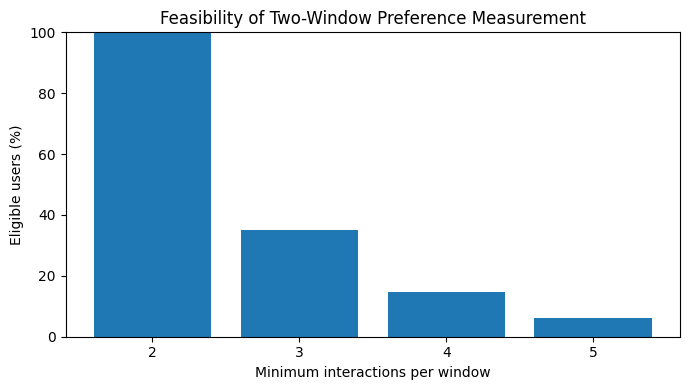

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.bar(
    feasibility["Minimum per window"].astype(str),
    feasibility["Eligibility rate"] * 100
)

plt.xlabel("Minimum interactions per window")
plt.ylabel("Eligible users (%)")
plt.title(
    "Feasibility of Two-Window Preference Measurement"
)

plt.ylim(0, 100)
plt.tight_layout()

plt.savefig(
    "figure4_measurement_feasibility.png",
    dpi=200
)

plt.show()

In [12]:
import pandas as pd
from huggingface_hub import hf_hub_download

repo = "SGJQovo/AgentRecBench"

names = [
    "amazon.csv",
    "amazon_case.csv",
    "amazon_sample.csv"
]

tables = {}

for name in names:
    path = hf_hub_download(
        repo_id=repo,
        filename=f"task/short_term/amazon/{name}",
        repo_type="dataset",
        local_files_only=True
    )

    table = pd.read_csv(path)
    tables[name] = table

    print(f"\n{name}")
    print("Rows:", len(table))
    print("Users:", table["user_id"].nunique())
    print("Items:", table["item_id"].nunique())
    print("Date range:",
          table["parsed_date"].min(),
          "to",
          table["parsed_date"].max())

# Compare user overlap between the three files
for i, name1 in enumerate(names):
    for name2 in names[i+1:]:
        users1 = set(tables[name1]["user_id"])
        users2 = set(tables[name2]["user_id"])

        print(
            f"\nUser overlap: {name1} vs {name2}:",
            len(users1 & users2)
        )


amazon.csv
Rows: 977
Users: 177
Items: 881
Date range: 2023-01-09 00:01:05.759 to 2023-01-14 22:53:10.421

amazon_case.csv
Rows: 458
Users: 100
Items: 437
Date range: 2023-01-09 00:01:05.759 to 2023-01-14 18:57:16.045

amazon_sample.csv
Rows: 558
Users: 100
Items: 527
Date range: 2023-01-09 00:01:05.759 to 2023-01-14 19:09:33.880

User overlap: amazon.csv vs amazon_case.csv: 100

User overlap: amazon.csv vs amazon_sample.csv: 100

User overlap: amazon_case.csv vs amazon_sample.csv: 100


In [13]:
# Compare exact interaction records across files

names = [
    "amazon.csv",
    "amazon_case.csv",
    "amazon_sample.csv"
]

# Use all shared columns to identify identical records
cols = ["user_id", "item_id", "rating", "date"]

records = {
    name: set(
        map(tuple, tables[name][cols].itertuples(
            index=False, name=None
        ))
    )
    for name in names
}

for name in names:
    print(f"{name}: {len(records[name])} unique records")

print("\nPairwise overlap:")

for i, name1 in enumerate(names):
    for name2 in names[i+1:]:
        common = records[name1] & records[name2]

        print(f"\n{name1} vs {name2}")
        print("Shared records:", len(common))
        print(
            "Overlap relative to first:",
            round(len(common) / len(records[name1]), 3)
        )
        print(
            "Overlap relative to second:",
            round(len(common) / len(records[name2]), 3)
        )

print("\nSubset checks:")
print(
    "case subset of amazon:",
    records["amazon_case.csv"].issubset(
        records["amazon.csv"]
    )
)
print(
    "sample subset of amazon:",
    records["amazon_sample.csv"].issubset(
        records["amazon.csv"]
    )
)
print(
    "case subset of sample:",
    records["amazon_case.csv"].issubset(
        records["amazon_sample.csv"]
    )
)

amazon.csv: 977 unique records
amazon_case.csv: 458 unique records
amazon_sample.csv: 558 unique records

Pairwise overlap:

amazon.csv vs amazon_case.csv
Shared records: 458
Overlap relative to first: 0.469
Overlap relative to second: 1.0

amazon.csv vs amazon_sample.csv
Shared records: 558
Overlap relative to first: 0.571
Overlap relative to second: 1.0

amazon_case.csv vs amazon_sample.csv
Shared records: 458
Overlap relative to first: 1.0
Overlap relative to second: 0.821

Subset checks:
case subset of amazon: True
sample subset of amazon: True
case subset of sample: True


In [14]:
import pandas as pd

cols = ["user_id", "item_id", "rating", "date"]

case = tables["amazon_case.csv"]
sample = tables["amazon_sample.csv"]

# Find records that appear in sample but not in case
extra = sample.merge(
    case[cols],
    on=cols,
    how="left",
    indicator=True
)

extra = extra[extra["_merge"] == "left_only"].drop(
    columns="_merge"
)

print("Extra records:", len(extra))
print("Users with extra records:", extra["user_id"].nunique())

print("\nExtra records per user:")
print(extra.groupby("user_id").size().value_counts().sort_index())

# Compare timestamps with the case history
case_latest = (
    case.groupby("user_id")["date"]
    .max()
    .rename("case_latest")
)

check = extra.join(case_latest, on="user_id")

print("\nExtra records later than all case records:",
      (check["date"] > check["case_latest"]).sum())

print("Extra records earlier or equal:",
      (check["date"] <= check["case_latest"]).sum())

print("\nSample of extra records:")
print(check[["user_id", "item_id", "parsed_date"]].head())

Extra records: 100
Users with extra records: 100

Extra records per user:
1    100
Name: count, dtype: int64

Extra records later than all case records: 100
Extra records earlier or equal: 0

Sample of extra records:
                         user_id     item_id              parsed_date
3   AFMUAVSZT7IIZE5MJATTQSZJATXQ  B00356J8KE  2023-01-09 04:10:40.420
8   AEQQZFX3NNGWSP26RJ5KPECI45KA  B081NVT11M  2023-01-09 16:07:04.668
17  AFPBQMFWFMV7NUIPD2OJCVKYKAUQ  B09ZQPXFPV  2023-01-14 18:48:52.173
21  AGJAYBLQYPYAVMFMG7OTDZY4WXTQ  B0094TLUC0  2023-01-13 09:29:32.446
28  AH32KDHBKYUGTQD6HEFPDQD7ECKA  B0BQMZ73RQ  2023-01-13 16:34:55.956


In [15]:
import json
from huggingface_hub import hf_hub_download

repo = "SGJQovo/AgentRecBench"

paths = [
    "task/short_term/amazon/groundtruth/groundtruth_0.json",
    "task/short_term/amazon/tasks/task_0.json"
]

for path in paths:
    print("\n" + "=" * 60)
    print("FILE:", path)

    try:
        local_path = hf_hub_download(
            repo_id=repo,
            filename=path,
            repo_type="dataset"
        )

        with open(local_path, "r", encoding="utf-8") as f:
            data = json.load(f)

        print("Top-level type:", type(data).__name__)

        if isinstance(data, dict):
            print("Keys:", list(data.keys()))
            for k, v in list(data.items())[:8]:
                print(k, ":", str(v)[:300])

        elif isinstance(data, list):
            print("Number of entries:", len(data))
            if data:
                print("First entry:", str(data[0])[:800])

    except Exception as e:
        print("ERROR:", type(e).__name__, str(e)[:300])


FILE: task/short_term/amazon/groundtruth/groundtruth_0.json


groundtruth_0.json:   0%|          | 0.00/36.0 [00:00<?, ?B/s]

Top-level type: dict
Keys: ['ground truth']
ground truth : B0BLL6MX9S

FILE: task/short_term/amazon/tasks/task_0.json


task_0.json:   0%|          | 0.00/654 [00:00<?, ?B/s]

Top-level type: dict
Keys: ['type', 'user_id', 'candidate_category', 'candidate_list', 'loc', 'data type']
type : recommendation
user_id : AE2I2KRNVKTC7GPT2PUWTOS35QCA
candidate_category : product
candidate_list : ['B008SBGK6Q', 'B06XZSFKZT', 'B002GYWBJG', 'B0BRRG1V8V', 'B00IA4L4BM', 'B0BLL6MX9S', 'B0774N9JKW', 'B019G53ZJW', 'B0047O2Q20', 'B000VTHSP0', 'B085D7Y3JV', 'B0B71W2D6J', 'B09C2DLCPG', 'B0137YSCRI', 'B07KJZRPSS', 'B005FKT70O', 'B07B9R77ZQ', 'B00VL6XMBQ', 'B08VNL4TG1', 'B076Z99R93']
loc : [-1, -1]
data type : real


In [16]:
import json
from huggingface_hub import hf_hub_download

repo = "SGJQovo/AgentRecBench"

task_path = hf_hub_download(
    repo_id=repo,
    filename="task/short_term/amazon/tasks/task_0.json",
    repo_type="dataset",
    local_files_only=True
)

gt_path = hf_hub_download(
    repo_id=repo,
    filename="task/short_term/amazon/groundtruth/groundtruth_0.json",
    repo_type="dataset",
    local_files_only=True
)

with open(task_path, encoding="utf-8") as f:
    task = json.load(f)

with open(gt_path, encoding="utf-8") as f:
    gt = json.load(f)["ground truth"]

user_id = task["user_id"]

# The 'extra' DataFrame was created in your previous cell.
matched = extra[
    (extra["user_id"] == user_id) &
    (extra["item_id"] == gt)
]

print("Task user:", user_id)
print("Ground truth item:", gt)
print("Matches in held-out records:", len(matched))

if len(matched):
    print("\nMatched interaction:")
    print(matched[
        ["user_id", "item_id", "parsed_date"]
    ].to_string(index=False))
else:
    print("\nNo exact match. We need to inspect the task construction.")

Task user: AE2I2KRNVKTC7GPT2PUWTOS35QCA
Ground truth item: B0BLL6MX9S
Matches in held-out records: 1

Matched interaction:
                     user_id    item_id             parsed_date
AE2I2KRNVKTC7GPT2PUWTOS35QCA B0BLL6MX9S 2023-01-11 07:48:16.377


In [17]:
import json
from huggingface_hub import hf_hub_download

path = hf_hub_download(
    repo_id="SGJQovo/AgentRecBench",
    filename="output_data_short/item.json",
    repo_type="dataset",
    local_files_only=True
)

target_items = set(
    tables["amazon_case.csv"]["item_id"]
)

matched = []

with open(path, "r", encoding="utf-8") as f:
    for line in f:
        record = json.loads(line)

        if record.get("item_id") in target_items:
            matched.append({
                "item_id": record.get("item_id"),
                "source": record.get("source"),
                "type": record.get("type"),
                "categories": record.get("categories"),
                "name": record.get("name")
            })

print("Target items:", len(target_items))
print("Matched metadata:", len(matched))

for record in matched[:5]:
    print(record)

Target items: 437
Matched metadata: 437
{'item_id': 'B0BGPK9CM7', 'source': 'amazon', 'type': 'product', 'categories': ['Industrial & Scientific', 'Additive Manufacturing Products', '3D Printing Supplies', '3D Printing Liquid'], 'name': None}
{'item_id': 'B09QC62FD3', 'source': 'amazon', 'type': 'product', 'categories': ['Industrial & Scientific', 'Additive Manufacturing Products', '3D Printers'], 'name': None}
{'item_id': 'B0BVVBT81S', 'source': 'amazon', 'type': 'product', 'categories': ['Industrial & Scientific', 'Fasteners', 'Screws', 'Socket Head Screws'], 'name': None}
{'item_id': 'B0BG75N8JQ', 'source': 'amazon', 'type': 'product', 'categories': ['Industrial & Scientific', 'Lab & Scientific Products', 'Lab Instruments & Equipment', 'Mixing & Blending Equipment', 'Lab Shakers & Accessories', 'Vortex Shakers'], 'name': None}
{'item_id': 'B0BF4TZZ59', 'source': 'amazon', 'type': 'product', 'categories': ['Industrial & Scientific', 'Hydraulics, Pneumatics & Plumbing', 'Fittings', 'V

After checking the dataset, I need to test consumer's preference shift score.

In [18]:

import pandas as pd
import numpy as np

# 1. Build a mapping from item ID to product category
# 'matched' contains the 437 matched item metadata records.
item_to_category = {}

for record in matched:
    categories = record.get("categories")

    if isinstance(categories, list) and len(categories) > 1:
        item_to_category[record["item_id"]] = categories[1]

# 2. Use historical interactions only
# Do NOT include the held-out target interaction.
history = tables["amazon_case.csv"].copy()

history["category"] = history["item_id"].map(
    item_to_category
)

history["parsed_date"] = pd.to_datetime(
    history["parsed_date"]
)

history = history.sort_values(
    ["user_id", "parsed_date", "item_id"]
)

print("Total historical interactions:", len(history))
print("Users:", history["user_id"].nunique())
print("Missing categories:", history["category"].isna().sum())

# 3. Define Total Variation Distance
def calculate_shift(past, recent):
    p = past.value_counts(normalize=True)
    q = recent.value_counts(normalize=True)

    all_categories = p.index.union(q.index)

    return 0.5 * sum(
        abs(p.get(c, 0) - q.get(c, 0))
        for c in all_categories
    )

# 4. Calculate the score for each eligible user
results = []

for user_id, group in history.groupby("user_id"):
    n = len(group)

    # Require at least 2 interactions in each window
    if n < 4:
        continue

    midpoint = n // 2

    past = group.iloc[:midpoint]["category"]
    recent = group.iloc[midpoint:]["category"]

    if past.isna().any() or recent.isna().any():
        continue

    score = calculate_shift(past, recent)

    results.append({
        "user_id": user_id,
        "n_interactions": n,
        "past_n": len(past),
        "recent_n": len(recent),
        "shift_score": score
    })

shift_df = pd.DataFrame(results)

print("\nEligible users:", len(shift_df))

if not shift_df.empty:
    print("\nPreference Shift Score Summary:")
    print(shift_df["shift_score"].describe())

    print("\nNumber of users with score = 0:",
          (shift_df["shift_score"] == 0).sum())

    print("Number of users with score = 1:",
          np.isclose(shift_df["shift_score"], 1).sum())

    print("\nFirst 10 results:")
    print(shift_df.head(10))

Total historical interactions: 458
Users: 100
Missing categories: 2

Eligible users: 52

Preference Shift Score Summary:
count    52.000000
mean      0.592537
std       0.326718
min       0.000000
25%       0.500000
50%       0.600000
75%       1.000000
max       1.000000
Name: shift_score, dtype: float64

Number of users with score = 0: 7
Number of users with score = 1: 14

First 10 results:
                        user_id  n_interactions  past_n  recent_n  shift_score
0  AE2I2KRNVKTC7GPT2PUWTOS35QCA               6       3         3     1.000000
1  AE4NJ32BCSI3T3W7YQHLKLIPOZCA               6       3         3     0.000000
2  AE5RMNTWOH3ZC5CDKQP6UHC4GLVQ               5       2         3     0.666667
3  AE767C6HYE6NSFRBT44R3M4X7PWQ               4       2         2     1.000000
4  AEBR6OLPMFYAUC5QCQW6XUFK3LRQ               6       3         3     0.000000
5  AEECMBRUJOD3TXYZSJ3YW3IMVTXA               5       2         3     0.666667
6  AEEUVHUGH2ZPYSG22RSWJFS5K5YA               5    

In [19]:

import pandas as pd
import numpy as np

# Group users by their number of historical interactions
summary = (
    shift_df.groupby("n_interactions")
    .agg(
        users=("user_id", "count"),
        mean_shift=("shift_score", "mean"),
        median_shift=("shift_score", "median"),
        share_score_one=(
            "shift_score",
            lambda x: np.isclose(x, 1).mean()
        )
    )
    .reset_index()
)

summary["share_score_one"] = (
    summary["share_score_one"] * 100
)

print(summary.to_string(index=False))

# Compare short vs longer histories
shift_df["history_group"] = np.where(
    shift_df["n_interactions"] <= 5,
    "4–5 interactions",
    "6+ interactions"
)

comparison = (
    shift_df.groupby("history_group")
    .agg(
        users=("user_id", "count"),
        mean_shift=("shift_score", "mean"),
        median_shift=("shift_score", "median"),
        share_score_one=(
            "shift_score",
            lambda x: np.isclose(x, 1).mean() * 100
        )
    )
)

print("\nShort vs longer histories:")
print(comparison)


 n_interactions  users  mean_shift  median_shift  share_score_one
              4     17    0.617647      0.500000        35.294118
              5     10    0.583333      0.666667        20.000000
              6     12    0.527778      0.666667        25.000000
              7      4    0.604167      0.708333        25.000000
              8      4    0.625000      0.625000        25.000000
              9      2    0.600000      0.600000         0.000000
             10      1    0.600000      0.600000         0.000000
             12      1    1.000000      1.000000       100.000000
             13      1    0.428571      0.428571         0.000000

Short vs longer histories:
                  users  mean_shift  median_shift  share_score_one
history_group                                                     
4–5 interactions     27    0.604938      0.500000         29.62963
6+ interactions      25    0.579143      0.666667         24.00000


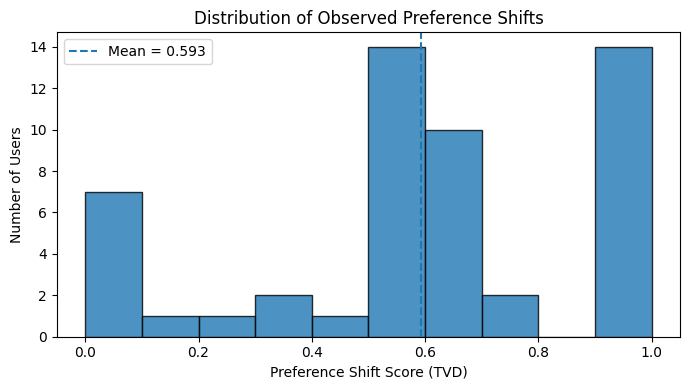

In [20]:

import matplotlib.pyplot as plt
import numpy as np

# Figure 2: Distribution of observed preference shifts
scores = shift_df["shift_score"].dropna()

plt.figure(figsize=(7, 4))
plt.hist(
    scores,
    bins=np.linspace(0, 1, 11),
    edgecolor="black",
    alpha=0.8
)

plt.axvline(
    scores.mean(),
    linestyle="--",
    linewidth=1.5,
    label=f"Mean = {scores.mean():.3f}"
)

plt.xlabel("Preference Shift Score (TVD)")
plt.ylabel("Number of Users")
plt.title("Distribution of Observed Preference Shifts")
plt.legend()
plt.tight_layout()

plt.savefig("figure2_preference_shift.png", dpi=300, bbox_inches="tight")
plt.show()

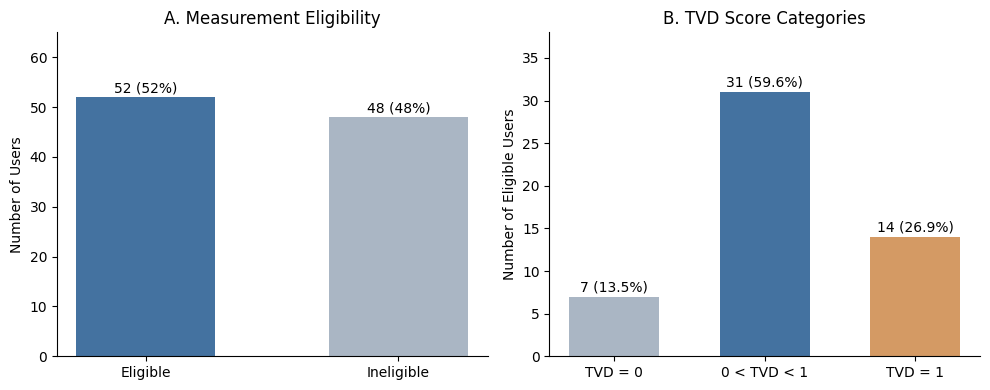

In [21]:

import matplotlib.pyplot as plt

# Observed pilot results
total_users = 100
eligible_users = 52
ineligible_users = 48

tvd_zero = 7
tvd_one = 14
tvd_middle = eligible_users - tvd_zero - tvd_one

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Panel A: Measurement eligibility
labels_a = ["Eligible", "Ineligible"]
values_a = [eligible_users, ineligible_users]

bars_a = axes[0].bar(
    labels_a, values_a,
    color=["#4472A0", "#AAB6C4"],
    width=0.55
)

axes[0].set_title("A. Measurement Eligibility")
axes[0].set_ylabel("Number of Users")
axes[0].set_ylim(0, 65)

for bar, value in zip(bars_a, values_a):
    axes[0].text(
        bar.get_x() + bar.get_width()/2,
        value + 1,
        f"{value} ({value/total_users:.0%})",
        ha="center"
    )

# Panel B: TVD score categories
labels_b = ["TVD = 0", "0 < TVD < 1", "TVD = 1"]
values_b = [tvd_zero, tvd_middle, tvd_one]

bars_b = axes[1].bar(
    labels_b, values_b,
    color=["#AAB6C4", "#4472A0", "#D49A64"],
    width=0.6
)

axes[1].set_title("B. TVD Score Categories")
axes[1].set_ylabel("Number of Eligible Users")
axes[1].set_ylim(0, 38)

for bar, value in zip(bars_b, values_b):
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        value + 0.6,
        f"{value} ({value/eligible_users:.1%})",
        ha="center"
    )

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    "figure4_pilot_feasibility.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [22]:
from google.colab import files

# Export user-level TVD measurements
shift_df.to_csv("preference_shift_scores.csv", index=False)

files.download("preference_shift_scores.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>